In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Understanding

### Melihat data

In [93]:
import pandas as pd
df = pd.read_csv("Food_Delivery_Times.csv")
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


- Ada kolom jarak, cuaca, traffic, jam pesan, kendaraan, waktu persiapan, pengalaman kurir, dan waktu pengiriman.

### Ukuran data

In [94]:
df.shape

(1000, 9)

- Ada 1.000 baris pesanan, dan 9 kolom.

### Tipe data

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


- Empat kolom hanya terisi 970 dari 1.000, jadi ada data kosong.

### Cek missing value

In [96]:
df.isna().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


- Weather, Traffic_Level, Time_of_Day, dan Courier_Experience_yrs masing-masing kosong 30 baris (sekitar 3%).

### Cek data duplikat

In [97]:
df.duplicated().sum()

np.int64(0)

In [98]:
df["Order_ID"].duplicated().sum()

np.int64(0)

- tidak ada data duplikat

### Riskasan Statistik

In [99]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


- Rata-rata waktu 56,7 menit dan median 55,5, hampir sama. Waktu terlama 153 menit, jauh di atas yang lain. Jarak 0,59-19,99 km, persiapan 5-29 menit, pengalaman kurir 0-9 tahun, dan tidak ada angka negatif.

### Cek isi kolom kategori

In [100]:
# cek kolom kategori dan jumlah tiap kolom

print(df["Weather"].value_counts(), "\n")
print(df["Traffic_Level"].value_counts(), "\n")
print(df["Time_of_Day"].value_counts(), "\n")
print(df["Vehicle_Type"].value_counts())

Weather
Clear    470
Rainy    204
Foggy    103
Snowy     97
Windy     96
Name: count, dtype: int64 

Traffic_Level
Medium    390
Low       383
High      197
Name: count, dtype: int64 

Time_of_Day
Morning      308
Evening      293
Afternoon    284
Night         85
Name: count, dtype: int64 

Vehicle_Type
Bike       503
Scooter    302
Car        195
Name: count, dtype: int64


- Cuaca cerah paling banyak (470). Traffic Medium 390, Low 383, High 197. Jam pesan Night paling sedikit (85). Kendaraan paling banyak Bike (503). Tidak ada salah ketik kategori.

### Boxplot waktu pengiriman (mencari outlier)

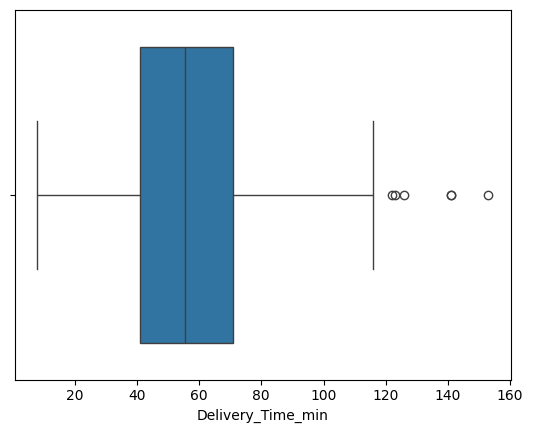

In [101]:
sns.boxplot(x=df["Delivery_Time_min"])    # titik terpisah di kanan = outlier
plt.show()

- Ada beberapa titik di kanan, tanda pesanan yang jauh lebih lama dari kebanyakan.

### Pesanan terlama (10)

In [102]:
df["Delivery_Time_min"].sort_values().tail(10)

,Delivery_Time_min
926,114
495,115
550,116
140,116
924,122
29,123
784,126
127,141
452,141
379,153


- Waktu pengiriman terlama mencapai 153 menit, sekitar 2,7 kali lipat rata-rata (56,7 menit). Sebagian besar dari 10 pesanan terlama ada di rentang 114-126 menit

### Pesanan ekstrem (outlier)

In [103]:
# menghitung batas outlier dengan IQR

q1 = df["Delivery_Time_min"].quantile(0.25)
q3 = df["Delivery_Time_min"].quantile(0.75)
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr

print("Q1 =", q1)
print("Q3 =", q3)
print("IQR =", iqr)
print("Batas atas =", batas_atas)

Q1 = 41.0
Q3 = 71.0
IQR = 30.0
Batas atas = 116.0


In [104]:
df[df["Delivery_Time_min"] > 116]

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
29,948,18.05,Clear,Medium,Evening,Scooter,10,7.0,123
127,446,18.97,Clear,Low,Evening,Car,25,4.0,141
379,814,18.46,Clear,NaN,NaN,Scooter,29,1.0,153
452,394,15.64,Rainy,Low,NaN,Bike,20,4.0,141
784,385,14.83,Rainy,Low,Morning,Car,19,4.0,126
924,428,17.81,Windy,High,Evening,Bike,21,4.0,122


- Ada 6 pesanan ekstrem, dan semuanya berjarak jauh (14,8-19 km). Traffic-nya tidak selalu padat (3 dari 6 Low), jadi jarak tampaknya penyebab utama.

- Enam pesanan ekstrem dipertahankan karena jumlahnya hanya 0,6% dan masuk akal (jarak jauh), bukan kesalahan input.

### Lihat berapa banyak baris yang terdampak missing value

In [105]:
# berapa pesanan yang punya data kosong

df.isna().any(axis=1).sum()

np.int64(117)

- ada 117 dari 1.000 pesanan (11,7%) yang memiliki setidaknya satu data kosong. jika baris ini dihapus, hampir 12% data hilang. karena itu, data kosong akan diisi, bukan dihapus.

# Data Preprocessing

### Membuat salinan data

In [106]:
df_clean = df.copy()    # fotokopi df, supaya data asli tetap aman

### Mengisi data kosong

In [107]:
df_clean["Weather"] = df_clean["Weather"].fillna("Clear")
df_clean["Traffic_Level"] = df_clean["Traffic_Level"].fillna("Medium")
df_clean["Time_of_Day"] = df_clean["Time_of_Day"].fillna("Morning")
df_clean["Courier_Experience_yrs"] = df_clean["Courier_Experience_yrs"].fillna(
    df_clean["Courier_Experience_yrs"].median())

- Kategori diisi nilai yang paling sering muncul (modus), angka diisi nilai tengah (median = 5) supaya tidak terpengaruh nilai ekstrem. Jumlah pesanan tetap 1.000.

### Hasil pengisian

In [108]:
df_clean.isna().sum()

,0
Order_ID,0
Distance_km,0
Weather,0
Traffic_Level,0
Time_of_Day,0
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,0
Delivery_Time_min,0


- Semua kolom data 0 missing value, data siap dipakai.

## Feature Engineering (membuat kolom baru)

#### Pengiriman yang lambat

In [109]:
df_clean["Slow_Delivery"] = (df_clean["Delivery_Time_min"] > 60).astype(int)
# "> 60" menghasilkan True/False, astype(int) mengubahnya jadi 1/0
df_clean["Slow_Delivery"].mean()   # rata-rata kolom 1/0 = persentase yang lambat

np.float64(0.415)

- Dengan batas 60 menit (asumsi), 41,5% pesanan tergolong lambat.

#### Kelompok jarak

In [110]:
df_clean["Distance_Group"] = pd.cut(df_clean["Distance_km"], bins=[0, 5, 10, 15, 20],
                                    labels=["0-5 km", "5-10 km", "10-15 km", "15-20 km"])
# pd.cut memotong angka jarak menjadi 4 kelompok

- Jarak dikelompokkan supaya pola per rentang jarak mudah dibandingkan.

# EDA

### Sebaran waktu pengiriman

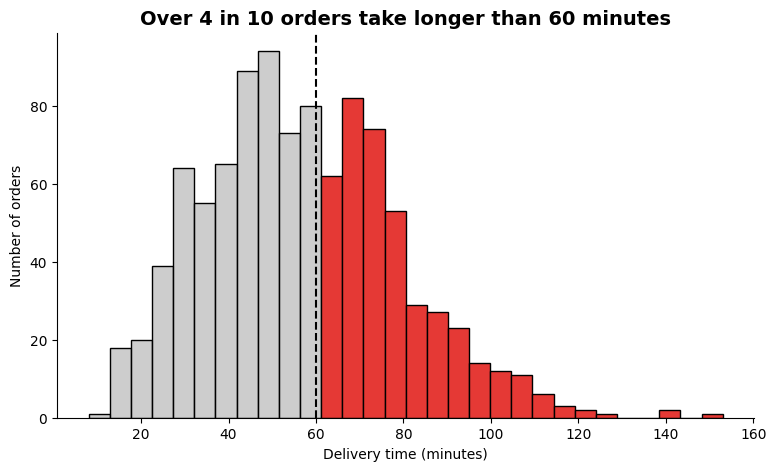

In [111]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_clean["Delivery_Time_min"], bins=30, color="#BDBDBD", ax=ax)
for p in ax.patches:
    if p.get_x() >= 60:
        p.set_facecolor("#E53935")
ax.axvline(60, color="black", linestyle="--")
ax.set_title("Over 4 in 10 orders take longer than 60 minutes", fontsize=14, fontweight="bold")
ax.set_xlabel("Delivery time (minutes)")
ax.set_ylabel("Number of orders")
sns.despine()
plt.show()

- Sebagian besar pesanan sampai dalam 40-70 menit dengan puncak di sekitar 50 menit. sekitar 41,5% pesanan melewati batas 60 menit (di kanan garis merah), dengan rata-rata waktu pengiriman 56,7 menit. artinya, hampir 4 dari 10 pesanan lambat, jadi masalahnya cukup besar. untuk batas 60 menit adalah asumsi sendiri, dekat dengan rata-rata.

### Jarak vs waktu pengiriman

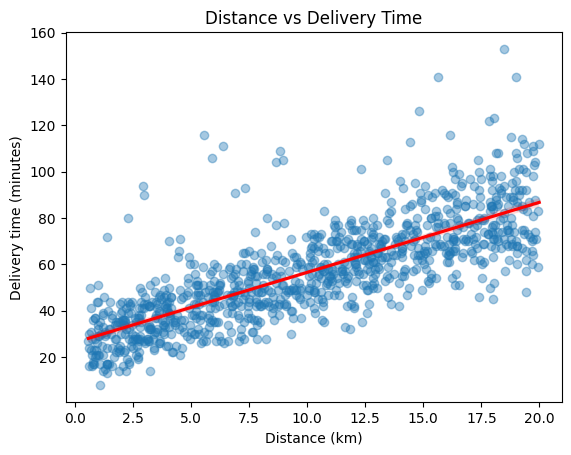

In [112]:
sns.regplot(data=df_clean, x="Distance_km", y="Delivery_Time_min",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.xlabel("Distance (km)")
plt.ylabel("Delivery time (minutes)")
plt.title("Distance vs Delivery Time")
plt.show()

- titik-titik naik ke kanan atas. garis merah menunjukkan arah naiknya. artinya makin jauh jarak, makin lama pengiriman. titik-titiknya masih menyebar, jadi ada faktor lain yang ikut berpengaruh. Itu yang kita cek berikutnya.

### Rata-rata waktu per kelompok jarak

In [113]:
df_clean.groupby("Distance_Group", observed=True)["Delivery_Time_min"].mean().round(1)
# groupby = kelompokkan, mean = rata-rata, round(1) = 1 angka di belakang koma

,Delivery_Time_min
Distance_Group,
0-5 km,34.3
5-10 km,49.0
10-15 km,63.4
15-20 km,79.4


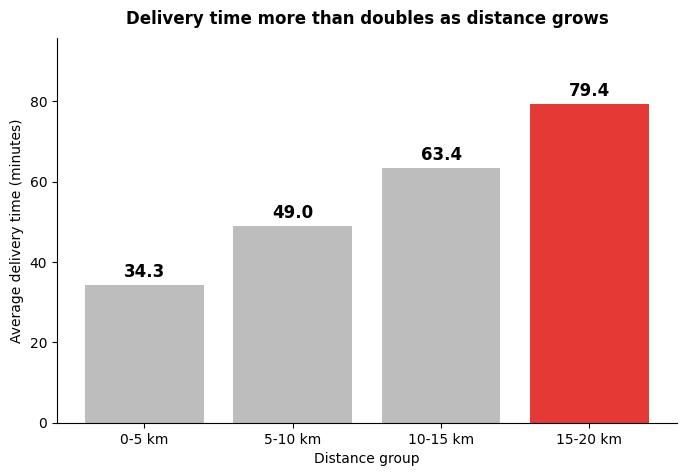

In [114]:
avg = df_clean.groupby("Distance_Group", observed=True)["Delivery_Time_min"].mean().round(1)
colors = ["#E53935" if g == "15-20 km" else "#BDBDBD" for g in avg.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg.index.astype(str), avg.values, color=colors)
ax.bar_label(bars, fmt="%.1f", fontsize=12, fontweight="bold", padding=3)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.set_title("Delivery time more than doubles as distance grows", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Distance group")
ax.set_ylabel("Average delivery time (minutes)")
sns.despine()
plt.show()

- batang naik dari kiri ke kanan. batang merah (15-20 km) paling tinggi. 34,3 menit (0-5 km), 49,0 (5-10 km), 63,4 (10-15 km), dan 79,4 (15-20 km). artinya, Pengiriman 15-20 km memakan waktu lebih dari dua kali lipat dibanding 0-5 km.

### Persentase pesanan lambat per kelompok jarak

In [115]:
(df_clean.groupby("Distance_Group", observed=True)["Slow_Delivery"].mean() * 100).round(1)
# rata-rata kolom 1/0 dikali 100 = persen

,Slow_Delivery
Distance_Group,
0-5 km,3.6
5-10 km,12.4
10-15 km,56.9
15-20 km,90.8


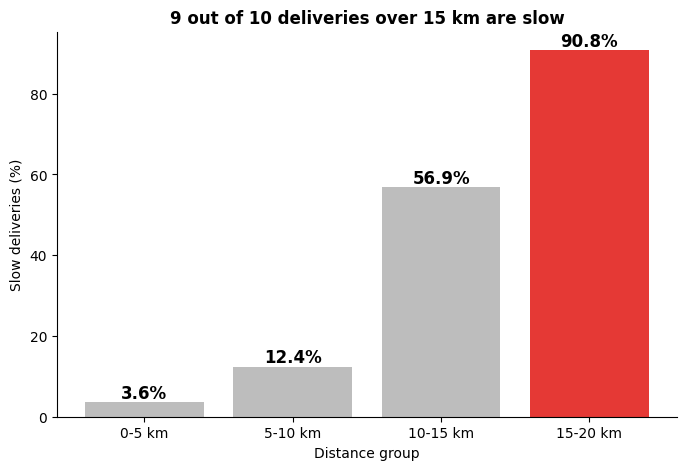

In [116]:
slow = (df_clean.groupby("Distance_Group", observed=True)["Slow_Delivery"].mean() * 100).round(1)

colors = ["#BDBDBD", "#BDBDBD", "#BDBDBD", "#E53935"]    # abu-abu x3, merah untuk 15-20 km

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(slow.index.astype(str), slow.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", fontsize=12, fontweight="bold")
ax.set_title("9 out of 10 deliveries over 15 km are slow", fontsize=12, fontweight="bold")
ax.set_xlabel("Distance group")
ax.set_ylabel("Slow deliveries (%)")
sns.despine()
plt.show()

- persentase lambat naik tajam di kelompok jarak jauh.3,6% (0-5 km), 12,4% (5-10 km), 56,9% (10-15 km), dan 90,8% (15-20 km). artinya mulai 10 km, lebih dari separuh pesanan lambat. pada 15-20 km, 9 dari 10 pesanan lambat. jarak adalah faktor paling menentukan.

### Rata-rata waktu per tingkat traffic

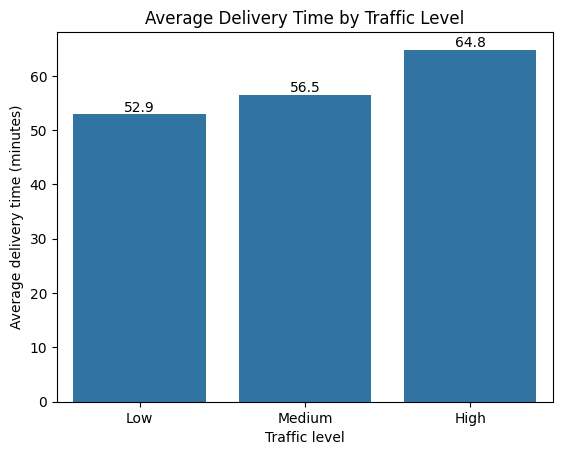

In [117]:
ax = sns.barplot(data=df_clean, x="Traffic_Level", y="Delivery_Time_min",
                 order=["Low", "Medium", "High"], errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic level")
plt.ylabel("Average delivery time (minutes)")
plt.show()

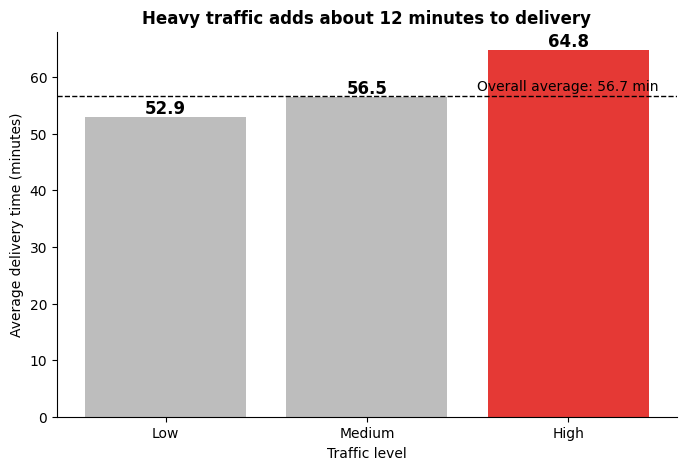

In [118]:
avg = df_clean.groupby("Traffic_Level")["Delivery_Time_min"].mean().round(1)[["Low", "Medium", "High"]]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg.index, avg.values, color=["#BDBDBD", "#BDBDBD", "#E53935"])   # High merah
ax.bar_label(bars, fmt="%.1f", fontsize=12, fontweight="bold")

rata2 = df_clean["Delivery_Time_min"].mean()                       # rata-rata seluruh pesanan (56,7)
ax.axhline(rata2, color="black", linestyle="--", linewidth=1)      # garis putus-putus
ax.text(2.45, rata2 + 1, "Overall average: 56.7 min", ha="right", fontsize=10)

ax.set_title("Heavy traffic adds about 12 minutes to delivery", fontsize=12, fontweight="bold")
ax.set_xlabel("Traffic level")
ax.set_ylabel("Average delivery time (minutes)")
sns.despine()
plt.show()

- waktu pengiriman naik saat traffic makin padat. Hanya traffic high yang di atas rata-rata keseluruhan (garis putus-putus). artinya traffic padat menambah sekitar 12 menit dibanding traffic lancar.

### Rata-rata waktu per cuaca

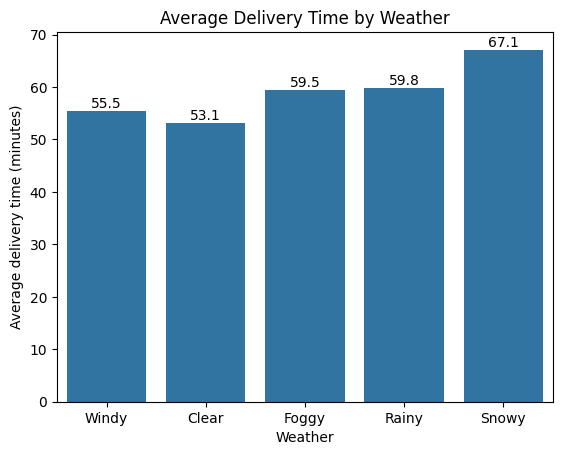

In [119]:
ax = sns.barplot(data=df_clean, x="Weather", y="Delivery_Time_min", errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Average delivery time (minutes)")
plt.show()

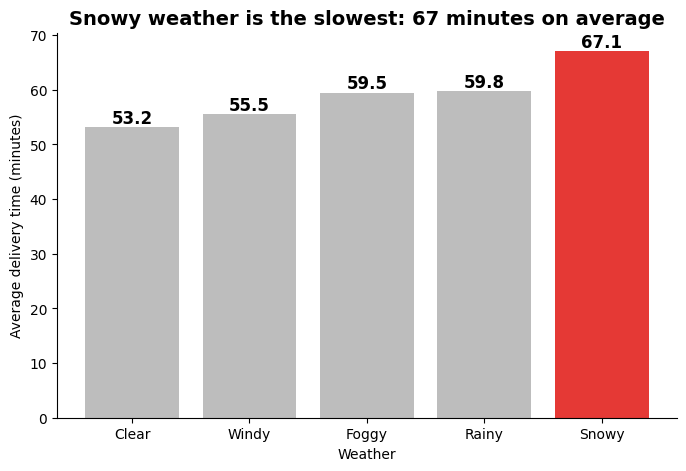

In [120]:
avg = df_clean.groupby("Weather")["Delivery_Time_min"].mean().round(1).sort_values()
colors = ["#E53935" if w == "Snowy" else "#BDBDBD" for w in avg.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg.index, avg.values, color=colors)
ax.bar_label(bars, fmt="%.1f", fontsize=12, fontweight="bold")
ax.set_title("Snowy weather is the slowest: 67 minutes on average", fontsize=14, fontweight="bold")
ax.set_xlabel("Weather")
ax.set_ylabel("Average delivery time (minutes)")
sns.despine()
plt.show()

- snowy paling lambat, batangnya merah. artinya saat salju, pengiriman sekitar 14 menit lebih lama daripada saat cuaca cerah. cuaca buruk lain (hujan dan kabut) juga lebih lambat sekitar 6 menit.

### Persentase pesanan lambat per traffic dan cuaca

In [121]:
print((df_clean.groupby("Traffic_Level")["Slow_Delivery"].mean() * 100).round(1), "\n")
print((df_clean.groupby("Weather")["Slow_Delivery"].mean() * 100).round(1))

Traffic_Level
High      54.3
Low       36.3
Medium    40.2
Name: Slow_Delivery, dtype: float64 

Weather
Clear    35.6
Foggy    47.6
Rainy    43.1
Snowy    59.8
Windy    43.8
Name: Slow_Delivery, dtype: float64


#### Presentase pesanan lambat per traffic

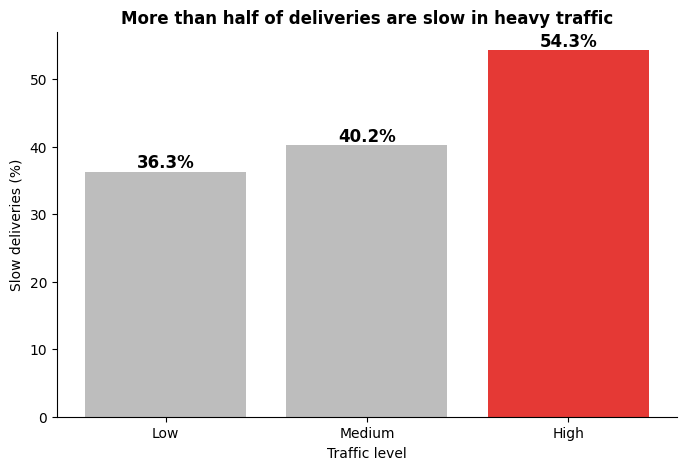

In [122]:
s = (df_clean.groupby("Traffic_Level")["Slow_Delivery"].mean() * 100).round(1)[["Low", "Medium", "High"]]
colors = ["#E53935" if t == "High" else "#BDBDBD" for t in s.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(s.index, s.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", fontsize=12, fontweight="bold")
ax.set_title("More than half of deliveries are slow in heavy traffic", fontsize=12, fontweight="bold")
ax.set_xlabel("Traffic level")
ax.set_ylabel("Slow deliveries (%)")
sns.despine()
plt.show()

#### Presentase pesanan lambat per weather

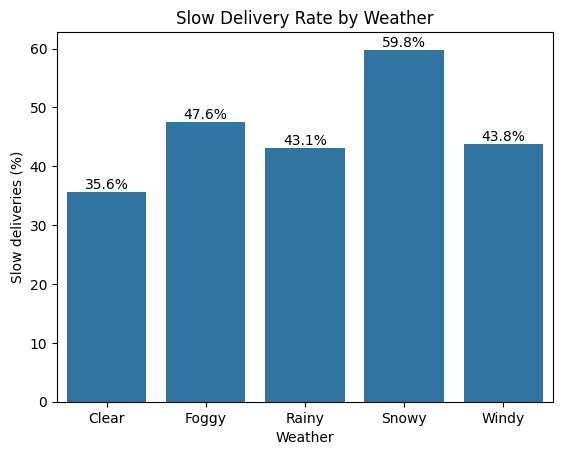

In [123]:
slow_weather = (df_clean.groupby("Weather")["Slow_Delivery"].mean() * 100).round(1)
ax = sns.barplot(x=slow_weather.index, y=slow_weather.values)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Slow Delivery Rate by Weather")
plt.xlabel("Weather")
plt.ylabel("Slow deliveries (%)")
plt.show()

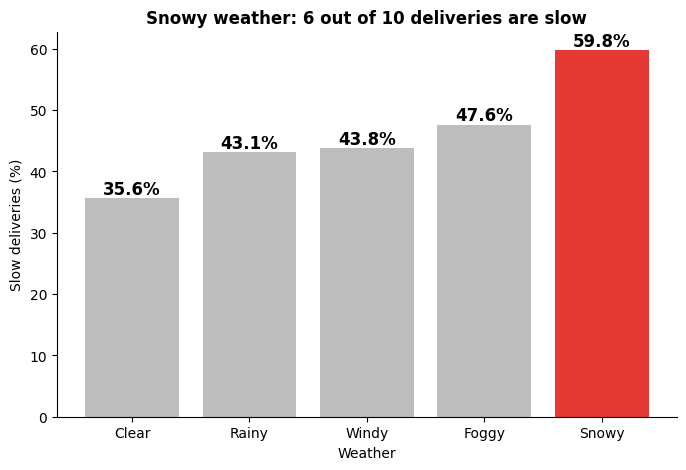

In [124]:
s = (df_clean.groupby("Weather")["Slow_Delivery"].mean() * 100).round(1).sort_values()
colors = ["#E53935" if w == "Snowy" else "#BDBDBD" for w in s.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(s.index, s.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", fontsize=12, fontweight="bold")
ax.set_title("Snowy weather: 6 out of 10 deliveries are slow", fontsize=12, fontweight="bold")
ax.set_xlabel("Weather")
ax.set_ylabel("Slow deliveries (%)")
sns.despine()
plt.show()

- batang merah (traffic high dan cuaca snowy) paling tinggi di masing-masing grafik. artinya, saat traffic padat, lebih dari separuh pesanan lambat. saat salju, sekitar 6 dari 10 pesanan lambat. Traffic padat dan cuaca buruk sama-sama menaikkan peluang pesanan lambat.

### Heatmap jarak and traffic

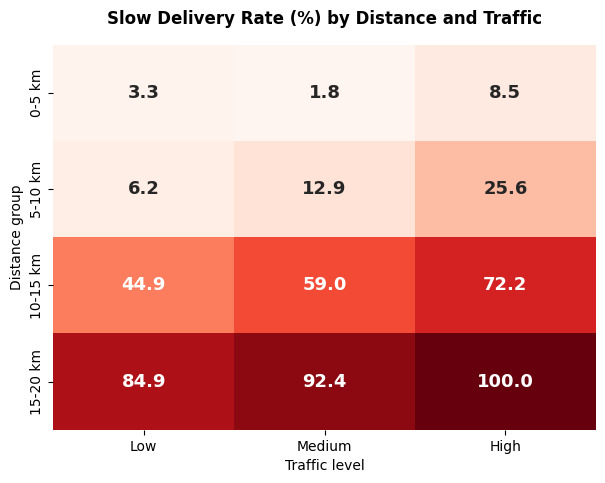

In [125]:
pivot = (df_clean.pivot_table(index="Distance_Group", columns="Traffic_Level",
                              values="Slow_Delivery", aggfunc="mean", observed=True) * 100).round(1)[["Low", "Medium", "High"]]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar=False,
            annot_kws={"size": 13, "weight": "bold"}, ax=ax)
ax.set_title("Slow Delivery Rate (%) by Distance and Traffic", fontsize=12, fontweight="bold", pad=15)
ax.set_xlabel("Traffic level")
ax.set_ylabel("Distance group")
plt.show()

- warna makin gelap ke arah bawah (jarak jauh) dan ke arah kanan (traffic padat). pada 15-20 km, persentase lambat sudah 84,9% saat traffic low, lalu 92,4% (medium) dan 100,0% (high). Pada 0-5 km, hanya 3,3% / 1,8% / 8,5%. artinya, arak jauh sudah sering lambat walau traffic lancar. traffic padat memperburuk semua kelompok jarak, dan efeknya paling terasa di jarak menengah (5-10 km: dari 6,2% naik ke 25,6%).

### Jam pesan dan jenis kendaraan

In [126]:
print(df_clean.groupby("Time_of_Day")["Delivery_Time_min"].mean().round(1), "\n")
print(df_clean.groupby("Vehicle_Type")["Delivery_Time_min"].mean().round(1))

Time_of_Day
Afternoon    56.1
Evening      57.5
Morning      57.0
Night        55.2
Name: Delivery_Time_min, dtype: float64 

Vehicle_Type
Bike       56.6
Car        58.2
Scooter    56.0
Name: Delivery_Time_min, dtype: float64


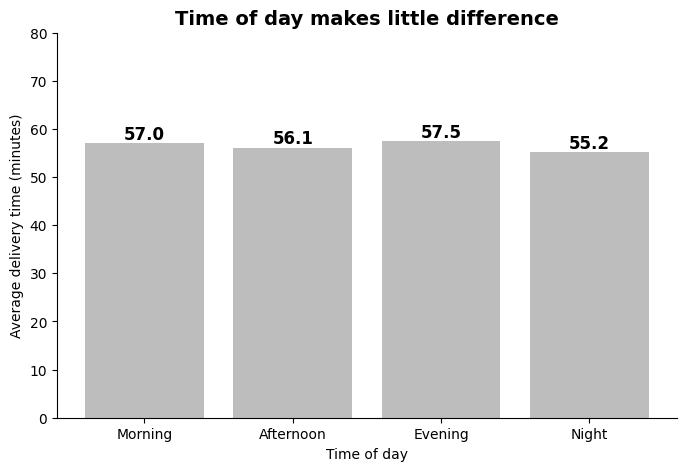

In [127]:
avg = df_clean.groupby("Time_of_Day")["Delivery_Time_min"].mean().round(1)[["Morning", "Afternoon", "Evening", "Night"]]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg.index, avg.values, color="#BDBDBD")
ax.bar_label(bars, fmt="%.1f", fontsize=12, fontweight="bold")
ax.set_ylim(0, 80)
ax.set_title("Time of day makes little difference", fontsize=14, fontweight="bold")
ax.set_xlabel("Time of day")
ax.set_ylabel("Average delivery time (minutes)")
sns.despine()
plt.show()

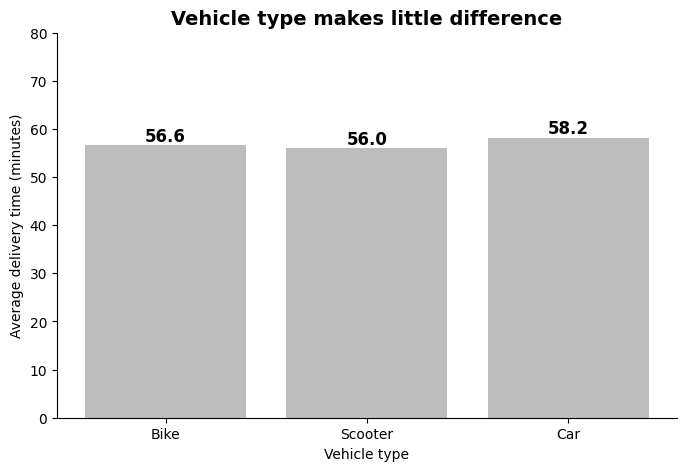

In [128]:
avg = df_clean.groupby("Vehicle_Type")["Delivery_Time_min"].mean().round(1)[["Bike", "Scooter", "Car"]]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avg.index, avg.values, color="#BDBDBD")
ax.bar_label(bars, fmt="%.1f", fontsize=12, fontweight="bold")
ax.set_ylim(0, 80)
ax.set_title("Vehicle type makes little difference", fontsize=14, fontweight="bold")
ax.set_xlabel("Vehicle type")
ax.set_ylabel("Average delivery time (minutes)")
sns.despine()
plt.show()

- yang terlihat: Semua batang abu-abu dan tingginya hampir sama. jam pesan 55,2 sampai 57,5 menit, jenis kendaraan 56,0 sampai 58,2 menit. artinya, selisihnya kecil, jadi jam pesan dan jenis kendaraan hampir tidak berpengaruh pada lamanya pengiriman. keduanya bukan prioritas untuk diperbaiki.

### Waktu persiapan vs waktu pengiriman

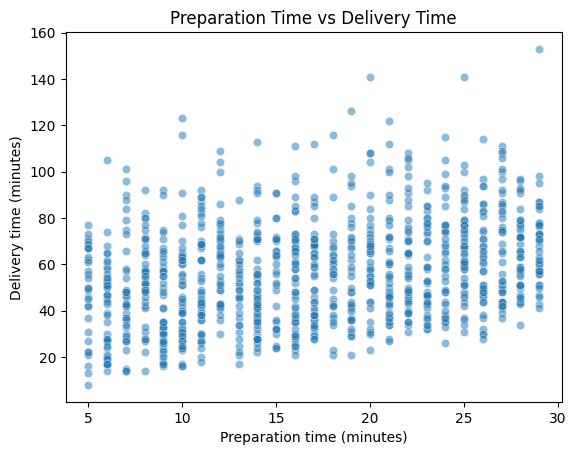

In [129]:
sns.scatterplot(data=df_clean, x="Preparation_Time_min", y="Delivery_Time_min", alpha=0.5)
plt.title("Preparation Time vs Delivery Time")
plt.xlabel("Preparation time (minutes)")
plt.ylabel("Delivery time (minutes)")
plt.show()

- titik-titik cenderung naik ke kanan, tetapi menyebar lebih lebar dibanding grafik jarak. artinya, restoran yang lama menyiapkan makanan ikut memperlambat pengiriman, tetapi pengaruhnya tidak sebesar jarak.

### Heatmap korelasi

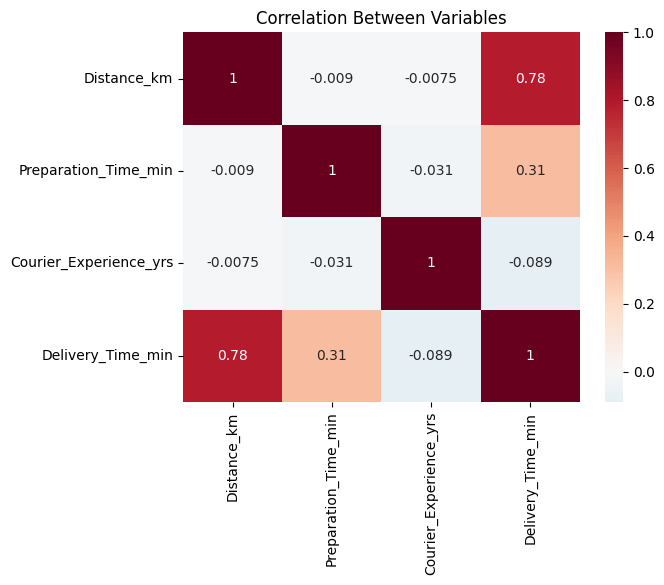

In [130]:
cols = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs", "Delivery_Time_min"]
sns.heatmap(df_clean[cols].corr(), annot=True, cmap="RdBu_r", center=0)
plt.title("Correlation Between Variables")
plt.show()

- warna merah tua berarti hubungan kuat, warna pucat berarti hubungan lemah. dilihat dari jarak 0,78, waktu persiapan 0,31, pengalaman kurir -0,09. artinya, korelasi berkisar -1 sampai 1, makin dekat ke 1 makin kuat hubungannya. disini jarak yang paling kuat, untuk waktu persiapan, dan pengalaman kurir berpengaruh kecil (tanda minus artinya makin berpengalaman, waktu sedikit berkurang).

### Kemiringan garis tren

In [131]:
import numpy as np

for kolom in ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]:
    slope, intercept = np.polyfit(df_clean[kolom], df_clean["Delivery_Time_min"], 1)
    print(kolom, "->", round(slope, 2))

Distance_km -> 3.03
Preparation_Time_min -> 0.94
Courier_Experience_yrs -> -0.69


- Tiap tambahan 1 km menambah sekitar 3 menit, tiap tambahan 1 menit persiapan menambah sekitar 0,9 menit, dan tiap tahun pengalaman kurir mengurangi sekitar 0,7 menit.

# Empat kolom baru untuk keperluan dashboard

In [132]:
df_clean["Delivery_Status"] = df_clean["Slow_Delivery"].map({1: "Slow", 0: "On time"})
df_clean["Traffic_Order"] = df_clean["Traffic_Level"].map({"Low": 1, "Medium": 2, "High": 3})
df_clean["Distance_Order"] = df_clean["Distance_Group"].astype(str).map({"0-5 km": 1, "5-10 km": 2, "10-15 km": 3, "15-20 km": 4})
df_clean["TimeOfDay_Order"] = df_clean["Time_of_Day"].map({"Morning": 1, "Afternoon": 2, "Evening": 3, "Night": 4})

In [133]:
df_clean.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min', 'Slow_Delivery', 'Distance_Group',
       'Delivery_Status', 'Traffic_Order', 'Distance_Order',
       'TimeOfDay_Order'],
      dtype='object')

In [134]:
print(len(df_clean.columns))
df_clean.columns.tolist()

15


['Order_ID',
 'Distance_km',
 'Weather',
 'Traffic_Level',
 'Time_of_Day',
 'Vehicle_Type',
 'Preparation_Time_min',
 'Courier_Experience_yrs',
 'Delivery_Time_min',
 'Slow_Delivery',
 'Distance_Group',
 'Delivery_Status',
 'Traffic_Order',
 'Distance_Order',
 'TimeOfDay_Order']

# Unggah file

In [135]:
df_clean.to_csv("Food_Delivery_Clean.csv", index=False)

from google.colab import files
files.download("Food_Delivery_Clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>